In [1]:
"""Basic tests for the A* maze solver."""
import unittest
import heapq


def manhattan(p1, p2):
    return abs(p1[0] - p2[0]) + abs(p1[1] - p2[1])


def astar(grid, start, goal):
    rows = len(grid)
    cols = len(grid[0])

    # Validation tests
    if grid[start[0]][start[1]] == 1:
        raise ValueError("Start cannot be a wall")
    if grid[goal[0]][goal[1]] == 1:
        raise ValueError("Goal cannot be a wall")

    # Priority queue stores (f_score, current_coords)
    # To prevent node comparison issues, we keep simple structures
    open_set = []
    heapq.heappush(open_set, (0, start))

    g_score = {start: 0}
    f_score = {start: manhattan(start, goal)}
    came_from = {}

    while open_set:
        _, current = heapq.heappop(open_set)

        if current == goal:
            path = []
            curr = current
            while curr in came_from:
                path.append(curr)
                curr = came_from[curr]
            path.append(start)
            path.reverse()
            return {"path": path, "cost": g_score[goal]}

        r, c = current
        for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
            neighbor = (r + dr, c + dc)
            nr, nc = neighbor
            if 0 <= nr < rows and 0 <= nc < cols:
                if grid[nr][nc] == 1: # Wall
                    continue

                tentative_g_score = g_score[current] + 1
                if tentative_g_score < g_score.get(neighbor, float('inf')):
                    came_from[neighbor] = current
                    g_score[neighbor] = tentative_g_score
                    f = tentative_g_score + manhattan(neighbor, goal)
                    f_score[neighbor] = f
                    heapq.heappush(open_set, (f, neighbor))

    return {"path": [], "cost": None}


class TestAStarMazeSolver(unittest.TestCase):
    def test_manhattan_distance(self):
        self.assertEqual(manhattan((0, 0), (2, 3)), 5)

    def test_finds_shortest_path(self):
        maze = [
            [0, 0, 0],
            [1, 1, 0],
            [0, 0, 0],
        ]
        result = astar(maze, (0, 0), (2, 2))
        self.assertEqual(result["cost"], 4)
        self.assertEqual(result["path"][0], (0, 0))
        self.assertEqual(result["path"][-1], (2, 2))

    def test_unreachable_goal(self):
        maze = [
            [0, 1, 0],
            [0, 1, 0],
            [0, 1, 0],
        ]
        result = astar(maze, (0, 0), (0, 2))
        self.assertEqual(result["path"], [])
        self.assertIsNone(result["cost"])

    def test_start_equals_goal(self):
        result = astar([[0]], (0, 0), (0, 0))
        self.assertEqual(result["path"], [(0, 0)])
        self.assertEqual(result["cost"], 0)

    def test_start_cannot_be_wall(self):
        with self.assertRaises(ValueError):
            astar([[1, 0]], (0, 0), (0, 1))

    def test_goal_cannot_be_wall(self):
        with self.assertRaises(ValueError):
            astar([[0, 1]], (0, 0), (0, 1))


if __name__ == "__main__":
    unittest.main(argv=['first-arg-is-ignored'], exit=False)

......
----------------------------------------------------------------------
Ran 6 tests in 0.004s

OK


Maze legend: S=start, G=goal, #=wall, *=path, +=explored, .=open
S * * + # + +
# # * + # + #
+ + * * * * *
+ # # # # # *
+ + + + * * *
+ # # # * # #
+ + + + * * G

Path found! Number of steps: 16
Path coordinates: (0, 0) -> (0, 1) -> (0, 2) -> (1, 2) -> (2, 2) -> (2, 3) -> (2, 4) -> (2, 5) -> (2, 6) -> (3, 6) -> (4, 6) -> (4, 5) -> (4, 4) -> (5, 4) -> (6, 4) -> (6, 5) -> (6, 6)


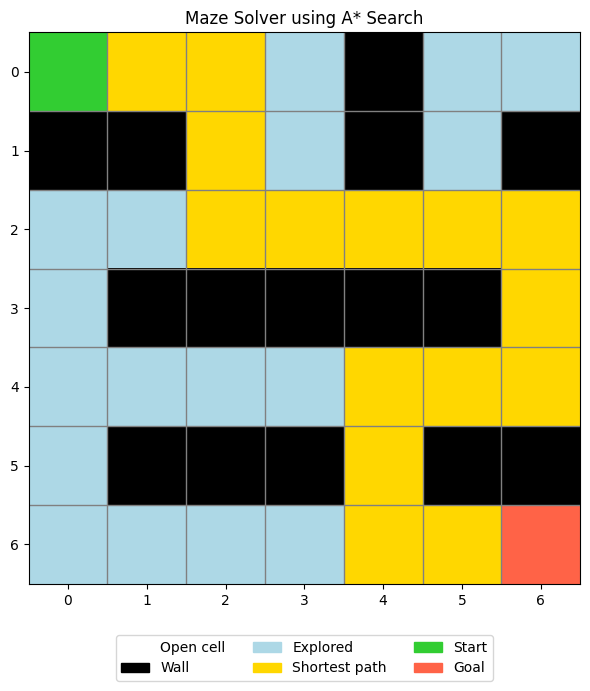

In [2]:
"""

Maze Solver using A* Search

Grid values:
    0 = walkable cell
    1 = wall

Coordinates are (row, column), starting from (0, 0).
"""

from heapq import heappush, heappop
from itertools import count
import argparse


# Example maze: 0 = open cell, 1 = wall
DEFAULT_MAZE = [
    [0, 0, 0, 0, 1, 0, 0],
    [1, 1, 0, 0, 1, 0, 1],
    [0, 0, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 1, 0],
    [0, 0, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 0, 1, 1],
    [0, 0, 0, 0, 0, 0, 0],
]
DEFAULT_START = (0, 0)
DEFAULT_GOAL = (6, 6)


def manhattan(a, b):
    """Estimate distance between two cells when movement is up/down/left/right."""
    return abs(a[0] - b[0]) + abs(a[1] - b[1])


def get_neighbors(maze, cell):
    """Return walkable neighboring cells (up, down, left, right)."""
    rows, cols = len(maze), len(maze[0])
    r, c = cell
    for nr, nc in ((r - 1, c), (r + 1, c), (r, c - 1), (r, c + 1)):
        if 0 <= nr < rows and 0 <= nc < cols and maze[nr][nc] == 0:
            yield (nr, nc)


def reconstruct_path(came_from, current):
    """Rebuild the route by following parent links from goal to start."""
    path = [current]
    while current in came_from:
        current = came_from[current]
        path.append(current)
    path.reverse()
    return path


def astar(maze, start, goal):
    """
    Find a shortest path with A*.

    Returns a dictionary with:
      path: list of (row, column) cells, or [] if no path exists
      visited: cells removed from the priority queue and explored
      cost: number of steps in the path, or None if unreachable
    Raises ValueError for malformed grids or invalid/wall start and goal.
    """
    if not maze or not maze[0]:
        raise ValueError("Maze must not be empty.")
    if any(len(row) != len(maze[0]) for row in maze):
        raise ValueError("Maze must be rectangular.")
    if any(value not in (0, 1) for row in maze for value in row):
        raise ValueError("Maze cells must be 0 (open) or 1 (wall).")

    rows, cols = len(maze), len(maze[0])

    def valid_cell(cell):
        return (
            isinstance(cell, tuple) and len(cell) == 2
            and isinstance(cell[0], int) and isinstance(cell[1], int)
            and 0 <= cell[0] < rows and 0 <= cell[1] < cols
        )

    if not valid_cell(start) or not valid_cell(goal):
        raise ValueError("Start and goal must be valid (row, column) coordinates.")
    if maze[start[0]][start[1]] == 1:
        raise ValueError("Start position is a wall.")
    if maze[goal[0]][goal[1]] == 1:
        raise ValueError("Goal position is a wall.")

    if start == goal:
        return {"path": [start], "visited": [start], "cost": 0}

    open_heap = []
    tie_breaker = count()
    heappush(open_heap, (manhattan(start, goal), 0, next(tie_breaker), start))
    came_from = {}
    g_score = {start: 0}
    closed = set()
    visited = []

    while open_heap:
        _, current_g, _, current = heappop(open_heap)

        # Ignore outdated queue entries.
        if current_g != g_score.get(current):
            continue
        if current in closed:
            continue

        closed.add(current)
        visited.append(current)

        if current == goal:
            path = reconstruct_path(came_from, current)
            return {"path": path, "visited": visited, "cost": len(path) - 1}

        for neighbor in get_neighbors(maze, current):
            tentative_g = g_score[current] + 1
            if tentative_g < g_score.get(neighbor, float("inf")):
                came_from[neighbor] = current
                g_score[neighbor] = tentative_g
                f_score = tentative_g + manhattan(neighbor, goal)
                heappush(
                    open_heap,
                    (f_score, tentative_g, next(tie_breaker), neighbor),
                )

    return {"path": [], "visited": visited, "cost": None}


def print_maze(maze, start, goal, path=None, visited=None):
    """Print a text visualization in the terminal."""
    path = set(path or [])
    visited = set(visited or [])
    for r, row in enumerate(maze):
        symbols = []
        for c, value in enumerate(row):
            cell = (r, c)
            if cell == start:
                symbols.append("S")
            elif cell == goal:
                symbols.append("G")
            elif value == 1:
                symbols.append("#")
            elif cell in path:
                symbols.append("*")
            elif cell in visited:
                symbols.append("+")
            else:
                symbols.append(".")
        print(" ".join(symbols))


def plot_maze(maze, start, goal, path=None, visited=None):
    """Display the maze using matplotlib. Install it with: pip install matplotlib."""
    try:
        import matplotlib.pyplot as plt
        from matplotlib.colors import ListedColormap
        from matplotlib.patches import Patch
    except ImportError as exc:
        raise RuntimeError(
            "Visualization needs matplotlib. Install it using: pip install matplotlib"
        ) from exc

    rows, cols = len(maze), len(maze[0])
    # 0=open, 1=wall, 2=explored, 3=path, 4=start, 5=goal
    display = [[1 if maze[r][c] else 0 for c in range(cols)] for r in range(rows)]
    for r, c in visited or []:
        if display[r][c] == 0:
            display[r][c] = 2
    for r, c in path or []:
        display[r][c] = 3
    display[start[0]][start[1]] = 4
    display[goal[0]][goal[1]] = 5

    colors = ["white", "black", "lightblue", "gold", "limegreen", "tomato"]
    cmap = ListedColormap(colors)
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.imshow(display, cmap=cmap, vmin=0, vmax=5)

    ax.set_xticks(range(cols))
    ax.set_yticks(range(rows))
    ax.set_xticks([x - 0.5 for x in range(1, cols)], minor=True)
    ax.set_yticks([y - 0.5 for y in range(1, rows)], minor=True)
    ax.grid(which="minor", color="gray", linewidth=1)
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.set_title("Maze Solver using A* Search")

    legend = [
        Patch(color="white", label="Open cell"),
        Patch(color="black", label="Wall"),
        Patch(color="lightblue", label="Explored"),
        Patch(color="gold", label="Shortest path"),
        Patch(color="limegreen", label="Start"),
        Patch(color="tomato", label="Goal"),
    ]
    ax.legend(handles=legend, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3)
    plt.tight_layout()
    plt.show()


def main():
    parser = argparse.ArgumentParser(description="Solve a grid maze using A*.")
    parser.add_argument(
        "--no-plot", action="store_true",
        help="Print the result in the terminal without opening a plot."
    )
    # Use parse_known_args() so we ignore Colab-specific kernel parameters
    args, _ = parser.parse_known_args()

    result = astar(DEFAULT_MAZE, DEFAULT_START, DEFAULT_GOAL)
    print("Maze legend: S=start, G=goal, #=wall, *=path, +=explored, .=open")
    print_maze(
        DEFAULT_MAZE, DEFAULT_START, DEFAULT_GOAL,
        result["path"], result["visited"]
    )

    if result["path"]:
        print(f"\nPath found! Number of steps: {result['cost']}")
        print("Path coordinates:", " -> ".join(map(str, result["path"])))
    else:
        print("\nNo path exists: the goal is unreachable.")

    if not args.no_plot:
        try:
            plot_maze(
                DEFAULT_MAZE, DEFAULT_START, DEFAULT_GOAL,
                result["path"], result["visited"]
            )
        except RuntimeError as error:
            print(f"\n{error}")
            print("The terminal result above is still available.")


if __name__ == "__main__":
    main()